In [22]:
import sys
sys.path.insert(0,"/workspace")

In [23]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [24]:
import importlib
import src.features.preprocessing as prep

importlib.reload(prep)

preprocessing = prep.preprocessing

In [25]:
import importlib
import src.features.preprocessing as prep

importlib.reload(prep)

preprocessing = prep.preprocessing

In [26]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [30]:
from src.data.loading import load_data , cg
from src.data.cleaning import clean_data
from src.models.training import training
from src.models.evaluation import evaluation

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [39]:
import importlib

importlib.reload(cg)

print(cg.DATA_PATH)

/workspace/data/raw/student_mental_health.csv


In [40]:
import sys
sys.path.insert(0,'/workspace')
df = load_data()

In [41]:
df = clean_data(df)

In [ ]:
models = {
    "random_forest" : RandomForestClassifier(),
    "svc" : SVC(),
    "knn" : KNeighborsClassifier()
}

In [43]:
for name , model in models.items():
    print("model : " , name )
    pipline , X_test , Y_test = training(df , model)
    resultat = evaluation(pipline , X_test , Y_test)

    display(resultat)

model :  random_forest


{'accuracy score : ': 0.6425,
 'confusion matrix : ': array([[104,   4,  32],
        [  3,  93,  40],
        [ 36,  28,  60]]),
 'classification report : ': '              precision    recall  f1-score   support\n\n        High       0.73      0.74      0.73       140\n         Low       0.74      0.68      0.71       136\n      Medium       0.45      0.48      0.47       124\n\n    accuracy                           0.64       400\n   macro avg       0.64      0.64      0.64       400\nweighted avg       0.65      0.64      0.64       400\n',
 'matthews corrcoef : ': 0.4638971071493852}

model :  svc


{'accuracy score : ': 0.6225,
 'confusion matrix : ': array([[91,  1, 34],
        [ 1, 85, 25],
        [51, 39, 73]]),
 'classification report : ': '              precision    recall  f1-score   support\n\n        High       0.64      0.72      0.68       126\n         Low       0.68      0.77      0.72       111\n      Medium       0.55      0.45      0.49       163\n\n    accuracy                           0.62       400\n   macro avg       0.62      0.65      0.63       400\nweighted avg       0.61      0.62      0.61       400\n',
 'matthews corrcoef : ': 0.4363153011384895}

model :  knn


{'accuracy score : ': 0.48,
 'confusion matrix : ': array([[81, 20, 51],
        [20, 74, 44],
        [42, 31, 37]]),
 'classification report : ': '              precision    recall  f1-score   support\n\n        High       0.57      0.53      0.55       152\n         Low       0.59      0.54      0.56       138\n      Medium       0.28      0.34      0.31       110\n\n    accuracy                           0.48       400\n   macro avg       0.48      0.47      0.47       400\nweighted avg       0.50      0.48      0.49       400\n',
 'matthews corrcoef : ': 0.21949311128736806}

In [44]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from src.features.preprocessing import preprocessing
from sklearn.pipeline import Pipeline

    

X = df.drop(columns=["Student_ID" , "Mental_Health_Risk"])
Y = df["Mental_Health_Risk"]

X_train , X_test , Y_train , Y_test = train_test_split(
    X,
    Y,
    random_state=42,
    test_size=0.2
)
param_grid = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}
print(X_train)
preprossesor = preprocessing(X_train)
pipline = Pipeline(steps=[
    ("preprocessor" , preprossesor),
    ('model' , RandomForestClassifier(random_state=42))
])


gridsearch = GridSearchCV(
    estimator=pipline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)
gridsearch.fit(X_train,Y_train)


      Age      Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week   GPA  \
968    21        Male              4          8.1                  27.5  3.03   
240    19  Non-binary              2          4.7                  19.5  2.25   
819    23        Male              2          7.5                  20.9  2.38   
692    19        Male              5          7.1                  35.0  2.86   
420    26      Female              5          5.3                  24.8  2.29   
...   ...         ...            ...          ...                   ...   ...   
1130   22      Female              3          8.4                  18.5  2.47   
1294   21      Female              1          5.6                  11.5  2.51   
860    21        Male              2          6.6                  26.5  2.54   
1459   22        Male              1          9.4                  17.9  2.62   
1126   22      Female              5          6.1                  23.0  2.65   

      Social_Media_Hours  S

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced', ...], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versioncha

In [45]:
gridsearch.best_score_

np.float64(0.7062001938450984)

In [46]:
best_model = gridsearch.best_estimator_

In [47]:
evaluation(best_model , X_test , Y_test)

{'accuracy score : ': 0.6725,
 'confusion matrix : ': array([[110,   2,  30],
        [  4,  90,  33],
        [ 29,  33,  69]]),
 'classification report : ': '              precision    recall  f1-score   support\n\n        High       0.77      0.77      0.77       142\n         Low       0.72      0.71      0.71       127\n      Medium       0.52      0.53      0.52       131\n\n    accuracy                           0.67       400\n   macro avg       0.67      0.67      0.67       400\nweighted avg       0.67      0.67      0.67       400\n',
 'matthews corrcoef : ': 0.5081202466518508}

In [48]:
from sklearn.metrics import roc_auc_score

Y_pred_proba = best_model.predict_proba(X_test)

auc = roc_auc_score(
    Y_test,
    Y_pred_proba,
    multi_class="ovr",
    average="macro"
)

print("ROC-AUC:", auc)


ROC-AUC: 0.8511220748786159


In [52]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 28.4 kB/s  0:06:13m0:00:0600:17
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 31.9 kB/s  0:03:21 eta 0:00:07
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.1 kB/s  0:00:48 eta 0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


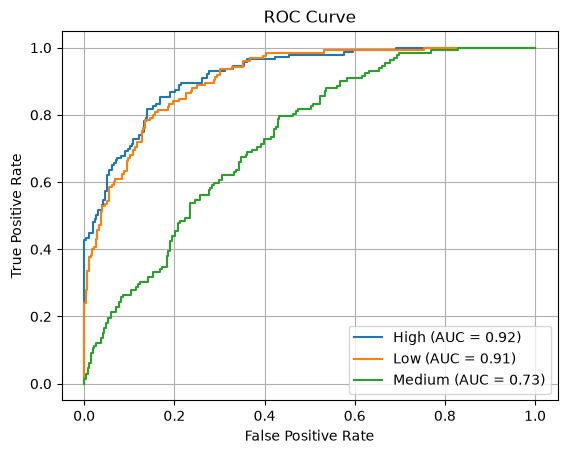

In [53]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_proba = best_model.predict_proba(X_test)

y_test_bin = label_binarize(Y_test, classes=best_model.classes_)

for i, classe in enumerate(best_model.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{classe} (AUC = {roc_auc:.2f})")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()



In [57]:

import joblib

joblib.dump(best_model , "workspace/models/best_model.joblib")

['workspace/models/best_model.joblib']